# **Assignment 5.- Convolutional Neural Network.**



Sandra Paola Aguilar Rangel 2178036

Andrea Elizondo Ocañas 2096175

Nelly Renata Garzon Medina 2114761

Erick Alejandro Cantu PLascencia 2105789

**Horario:** Tuesday N4  
  

**Objective:** To train and evaluate a convolutional neural network capable of classifying images of handwritten digits from the MNIST dataset.

Instructions: execute the cells in order, from the first to the last.


## 1. Cargar bibliotecas

Importamos TensorFlow/Keras para construir la red neuronal, Matplotlib para visualizar imágenes y gráficas, y NumPy para trabajar con arreglos numéricos.

In [11]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

print("Versión de TensorFlow:", tf.__version__)
print("GPU disponible:", len(tf.config.list_physical_devices('GPU')) > 0)


Versión de TensorFlow: 2.21.0
GPU disponible: False


## 2. Cargar los datos

MNIST contiene 60,000 imágenes para entrenamiento y 10,000 para prueba. Cada imagen representa un dígito del 0 al 9 y tiene un tamaño de 28 × 28 píxeles.

In [12]:
(train_data, train_labels), (test_data, test_labels) = keras.datasets.mnist.load_data()

print("Dimensiones de imágenes de entrenamiento:", train_data.shape)
print("Dimensiones de etiquetas de entrenamiento:", train_labels.shape)
print("Dimensiones de imágenes de prueba:", test_data.shape)
print("Dimensiones de etiquetas de prueba:", test_labels.shape)


Dimensiones de imágenes de entrenamiento: (60000, 28, 28)
Dimensiones de etiquetas de entrenamiento: (60000,)
Dimensiones de imágenes de prueba: (10000, 28, 28)
Dimensiones de etiquetas de prueba: (10000,)


## 3. Preprocesamiento de datos

Normalizamos los valores de los píxeles de 0–255 a 0–1. Después agregamos el canal de color (escala de grises), porque la CNN espera imágenes con tres dimensiones: alto, ancho y canales.

In [13]:
train_data = train_data.astype("float32") / 255.0
test_data = test_data.astype("float32") / 255.0

# MNIST está en escala de grises: se agrega un canal.
train_data = np.expand_dims(train_data, axis=-1)
test_data = np.expand_dims(test_data, axis=-1)

print("Nueva forma de train_data:", train_data.shape)
print("Nueva forma de test_data:", test_data.shape)


Nueva forma de train_data: (60000, 28, 28, 1)
Nueva forma de test_data: (10000, 28, 28, 1)


### Visualizar algunos datos

La siguiente celda muestra nueve imágenes del conjunto de entrenamiento y su etiqueta real.

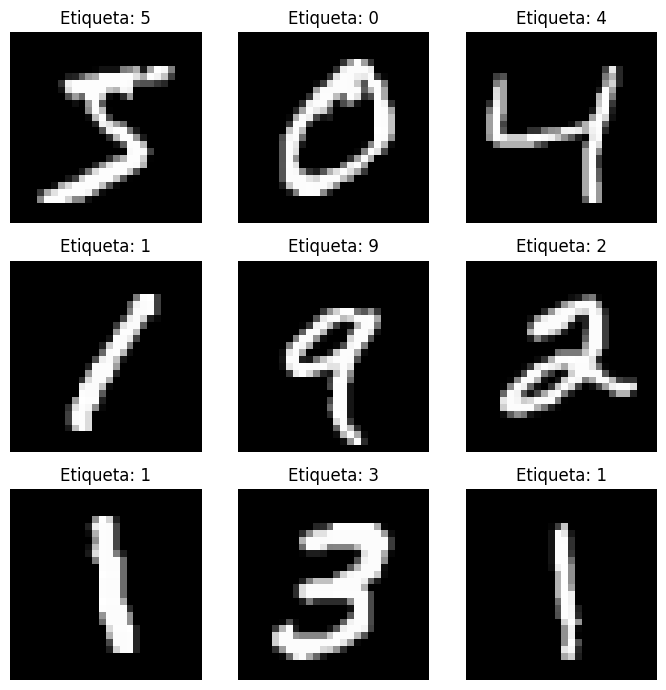

In [4]:
plt.figure(figsize=(7, 7))
for i in range(9):
    plt.subplot(3, 3, i + 1)
    plt.imshow(train_data[i].squeeze(), cmap="gray")
    plt.title(f"Etiqueta: {train_labels[i]}")
    plt.axis("off")
plt.tight_layout()
plt.show()


## 4. Selección y entrenamiento del modelo

Se propone una CNN con dos capas convolucionales, capas de reducción de dimensión (MaxPooling), una capa Dropout para ayudar a reducir el sobreajuste, una capa densa y una capa de salida de 10 neuronas.

- **Función de activación de salida:** softmax, para obtener probabilidades para las diez clases.
- **Función de pérdida:** sparse categorical crossentropy, adecuada porque las etiquetas son números enteros de 0 a 9.
- **Optimizador:** Adam.
- **Métrica:** accuracy (precisión de clasificación).


In [5]:
model = keras.Sequential([
    keras.Input(shape=(28, 28, 1)),
    layers.Conv2D(32, kernel_size=(3, 3), activation="relu"),
    layers.MaxPooling2D(pool_size=(2, 2)),
    layers.Conv2D(64, kernel_size=(3, 3), activation="relu"),
    layers.MaxPooling2D(pool_size=(2, 2)),
    layers.Flatten(),
    layers.Dropout(0.25),
    layers.Dense(128, activation="relu"),
    layers.Dense(10, activation="softmax")
])

model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

In [14]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Entrenamiento: 5 épocas, con 10% de los datos de entrenamiento para validación.
history = model.fit(
    train_data,
    train_labels,
    epochs=5,
    batch_size=128,
    validation_split=0.1,
    verbose=1
)


Epoch 1/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 46s 106ms/step - accuracy: 0.9899 - loss: 0.0310 - val_accuracy: 0.9902 - val_loss: 0.0352
Epoch 2/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 46s 108ms/step - accuracy: 0.9917 - loss: 0.0261 - val_accuracy: 0.9905 - val_loss: 0.0332
Epoch 3/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 83s 110ms/step - accuracy: 0.9930 - loss: 0.0215 - val_accuracy: 0.9920 - val_loss: 0.0322
Epoch 4/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 81s 106ms/step - accuracy: 0.9940 - loss: 0.0173 - val_accuracy: 0.9918 - val_loss: 0.0318
Epoch 5/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 44s 105ms/step - accuracy: 0.9946 - loss: 0.0157 - val_accuracy: 0.9922 - val_loss: 0.0301


### Gráficas del entrenamiento

Se muestran la precisión y la pérdida durante las épocas de entrenamiento y validación.

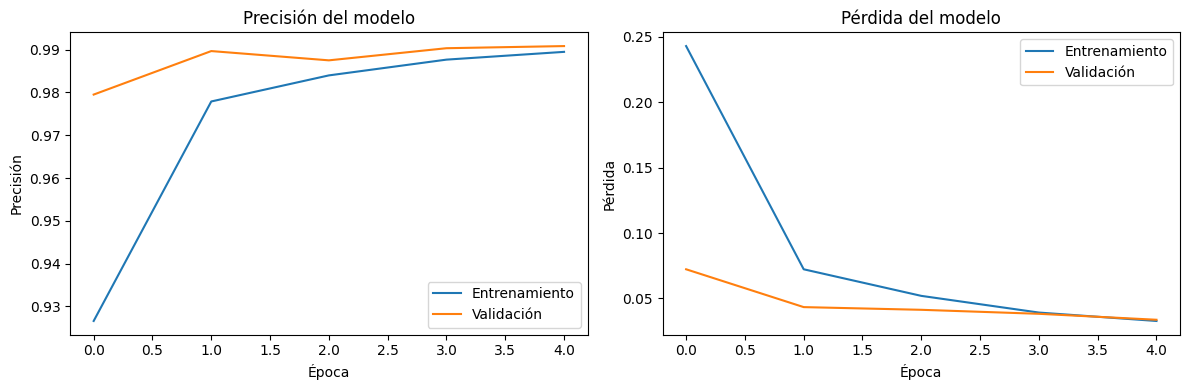

In [7]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Entrenamiento")
plt.plot(history.history["val_accuracy"], label="Validación")
plt.title("Precisión del modelo")
plt.xlabel("Época")
plt.ylabel("Precisión")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Entrenamiento")
plt.plot(history.history["val_loss"], label="Validación")
plt.title("Pérdida del modelo")
plt.xlabel("Época")
plt.ylabel("Pérdida")
plt.legend()

plt.tight_layout()
plt.show()


## 5. Pruebas y evaluación del modelo

Utilizamos `model.evaluate()` con el conjunto de prueba, que no se utilizó para ajustar los pesos durante el entrenamiento. La precisión obtenida se imprime como porcentaje.

In [15]:
test_loss, test_accuracy = model.evaluate(test_data, test_labels, verbose=0)

print(f"Pérdida en prueba: {test_loss:.4f}")
print(f"Precisión en prueba: {test_accuracy * 100:.2f}%")


Pérdida en prueba: 0.0255
Precisión en prueba: 99.21%


## 6. Realizar cinco predicciones

Seleccionamos cinco imágenes del conjunto de prueba. Para cada una se muestra la predicción de la red y el valor real. Si ambos números coinciden, la predicción fue correcta.

Imagen 1: predicción = 7, valor real = 7, resultado = Correcta
Imagen 2: predicción = 2, valor real = 2, resultado = Correcta
Imagen 3: predicción = 1, valor real = 1, resultado = Correcta
Imagen 4: predicción = 0, valor real = 0, resultado = Correcta
Imagen 5: predicción = 4, valor real = 4, resultado = Correcta


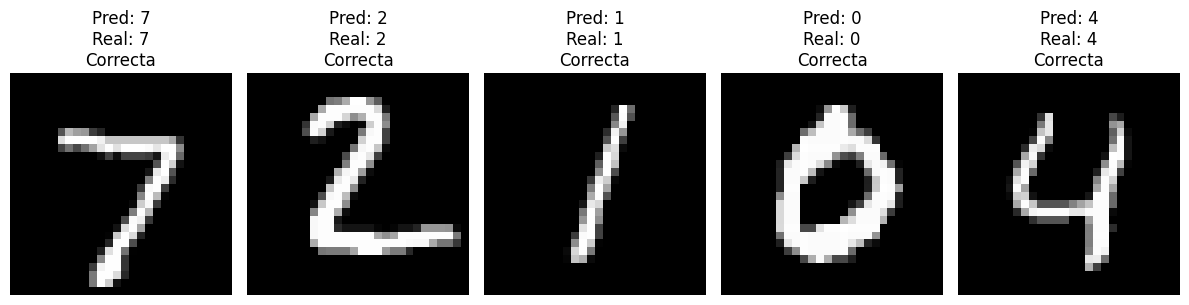

In [16]:
probabilities = model.predict(test_data[:5], verbose=0)
predictions = np.argmax(probabilities, axis=1)

plt.figure(figsize=(12, 3))
for i in range(5):
    predicted = int(predictions[i])
    actual = int(test_labels[i])
    result = "Correcta" if predicted == actual else "Incorrecta"

    plt.subplot(1, 5, i + 1)
    plt.imshow(test_data[i].squeeze(), cmap="gray")
    plt.title(f"Pred: {predicted}\nReal: {actual}\n{result}")
    plt.axis("off")

    print(f"Imagen {i+1}: predicción = {predicted}, valor real = {actual}, resultado = {result}")

plt.tight_layout()
plt.show()


## 7. Guardar el modelo entrenado (opcional)

Esta celda guarda el modelo en formato Keras dentro de la sesión de Colab. Puedes descargarlo desde el panel de archivos si también deseas conservarlo.

In [10]:
model.save("modelo_CNN_MNIST.keras")
print("Modelo guardado como modelo_CNN_MNIST.keras")


Modelo guardado como modelo_CNN_MNIST.keras


## 8. Conclusión del cuaderno

La red neuronal convolucional fue entrenada con imágenes del conjunto MNIST para clasificar dígitos escritos a mano. La precisión final debe reportarse con el valor que aparezca al ejecutar la evaluación. Las cinco predicciones permiten comparar la clasificación del modelo con las etiquetas reales y comprobar visualmente su funcionamiento.

**Importante:** antes de entregar, ejecuta todas las celdas y verifica que no aparezcan errores. Después descarga el cuaderno como `CNN.ipynb` y súbelo a la carpeta `Asignaciones` de tu repositorio de GitHub.
